In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
SRC = ROOT / "src"

sys.path.insert(0, str(SRC))

from scipy.stats import norm
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.optimize import brentq

from utils.data_generation import generate_two_estimator_data
from utils.coverage import psi_two_estimator, ci_delta_two_estimator, ci_tau_two_estimator

In [48]:
B = 10_000
tau = 0
delta = 0.015
sigma1 = 1
sigma2 = 1
rho = 0
n_1 = 500
n_2 = 1000
alpha = 0.05
gamma = 0.05
rng = np.random.default_rng()


In [10]:
# Record lower and upper bounds of the confidence intervals.
ci_eb_array = np.zeros((B, 2))
ci_regular_array = np.zeros((B, 2))
estimates_eb_array = np.zeros(B)
estimates_regular_array = np.zeros(B)

for i in range(B):
    y, _, _, _ = generate_two_estimator_data(
        n1=n_1, n2=n_2, mu=tau, delta_f=delta,
        sigma1=sigma1, sigma2=sigma2, rho=rho, rng=rng,
        return_samples=True,
    )

    estimate_eb = y[0] + psi_two_estimator(y, n1=n_1, n2=n_2, sigma1=sigma1, sigma2=sigma2, rho=rho) * (y[1] - y[0])
    estimates_eb_array[i] = estimate_eb
    estimates_regular_array[i] = y[0]

    ci_eb = ci_tau_two_estimator(
        y, n1=n_1, n2=n_2, sigma1=sigma1, sigma2=sigma2,
        rho=rho, alpha=alpha, gamma=gamma,
    )
    # Use the regular normal interval for the first estimator as a comparison.
    z = norm.ppf(1 - alpha / 2)
    ci_regular = (y[0] - z * sigma1 / np.sqrt(n_1), y[0] + z * sigma1 / np.sqrt(n_1))

    ci_eb_array[i, :] = ci_eb
    ci_regular_array[i, :] = ci_regular


KeyboardInterrupt: 

In [38]:
mse_eb = np.mean((estimates_eb_array - tau) ** 2)
mse_regular = np.mean((estimates_regular_array - tau) ** 2)

mse_eb, mse_regular

(np.float64(0.00016970686880942804), np.float64(0.00020139921041134414))

In [40]:
# check coverage of the confidence intervals
coverage_eb = np.mean((ci_eb_array[:, 0] <= tau) & (ci_eb_array[:, 1] >= tau))
coverage_regular = np.mean((ci_regular_array[:, 0] <= tau) & (ci_regular_array[:, 1] >= tau))

avg_length_eb = np.mean(ci_eb_array[:, 1] - ci_eb_array[:, 0])
avg_length_regular = np.mean(ci_regular_array[:, 1] - ci_regular_array[:, 0])

In [41]:
coverage_eb, coverage_regular

(np.float64(0.9936), np.float64(0.9516))

In [42]:
avg_length_eb, avg_length_regular

(np.float64(0.7385570829044424), np.float64(0.5543615297398716))

## Where does the MSE of EB cross with the standard estimator?

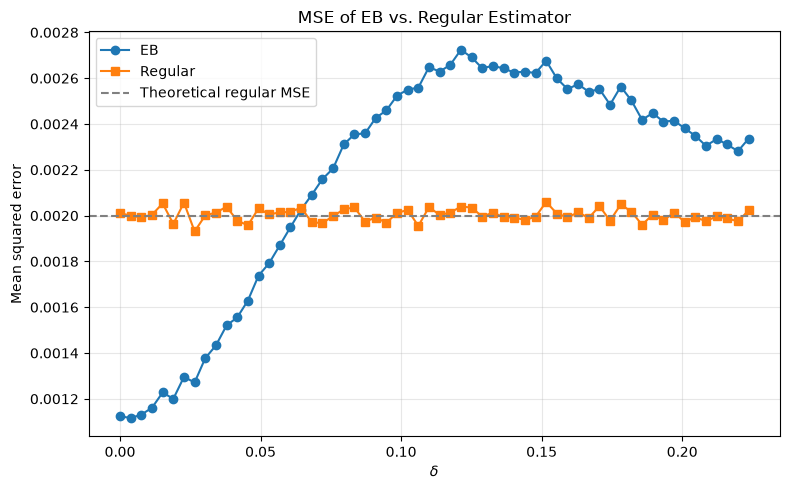

In [49]:
delta_grid = np.linspace(1e-6, 5 / np.sqrt(n_1), 60)

mse_eb = np.zeros(len(delta_grid))
mse_regular = np.zeros(len(delta_grid))

for j, delta in enumerate(delta_grid):
    estimates_eb_array = np.zeros(B)
    estimates_regular_array = np.zeros(B)

    for i in range(B):
        y, _, _, _ = generate_two_estimator_data(
            n1=n_1, n2=n_2, mu=tau, delta_f=delta,
            sigma1=sigma1, sigma2=sigma2, rho=rho,
            rng=rng, return_samples=True,
        )

        estimates_eb_array[i] = (
            y[0]
            + psi_two_estimator(
                y, n1=n_1, n2=n_2,
                sigma1=sigma1, sigma2=sigma2, rho=rho,
            ) * (y[1] - y[0])
        )
        estimates_regular_array[i] = y[0]

    mse_eb[j] = np.mean((estimates_eb_array - tau)**2)
    mse_regular[j] = np.mean((estimates_regular_array - tau)**2)

plt.figure(figsize=(8, 5))
plt.plot(delta_grid, mse_eb, marker="o", label="EB")
plt.plot(delta_grid, mse_regular, marker="s", label="Regular")
plt.axhline(sigma1**2 / n_1, color="gray",
            linestyle="--", label="Theoretical regular MSE")

plt.xlabel(r"$\delta$")
plt.ylabel("Mean squared error")
plt.title("MSE of EB vs. Regular Estimator")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

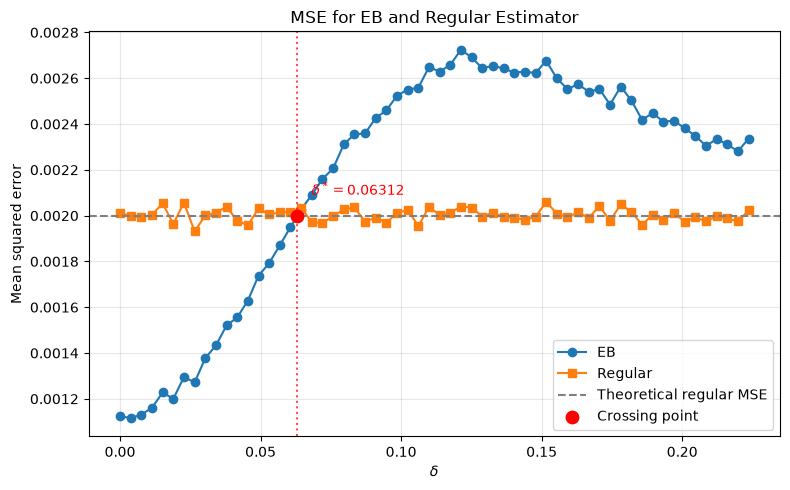

Estimated crossing points: [0.0631213984669659]


In [50]:
mse_diff = mse_eb - sigma1**2 / n_1

# Find all crossing points by linear interpolation.
crossings = []
for j in range(len(delta_grid) - 1):
    if mse_diff[j] * mse_diff[j + 1] < 0:
        delta_cross = brentq(
            lambda d: np.interp(d, delta_grid, mse_diff),
            delta_grid[j],
            delta_grid[j + 1],
        )
        crossings.append(delta_cross)

plt.figure(figsize=(8, 5))
plt.plot(delta_grid, mse_eb, marker="o", label="EB")
plt.plot(delta_grid, mse_regular, marker="s", label="Regular")
plt.axhline(
    sigma1**2 / n_1, color="gray",
    linestyle="--", label="Theoretical regular MSE"
)

for k, delta_cross in enumerate(crossings):
    mse_cross = np.interp(delta_cross, delta_grid, mse_eb)

    plt.scatter(delta_cross, mse_cross, color="red",
                s=80, zorder=5,
                label="Crossing point" if k == 0 else None)
    plt.axvline(delta_cross, color="red", linestyle=":", alpha=0.7)

    plt.annotate(
        rf"$\delta^*={delta_cross:.5f}$",
        (delta_cross, mse_cross),
        xytext=(10, 15), textcoords="offset points",
        color="red"
    )

plt.xlabel(r"$\delta$")
plt.ylabel("Mean squared error")
plt.title("MSE for EB and Regular Estimator")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Estimated crossing points:", crossings)